<a href="https://colab.research.google.com/github/Mithun-J/cases-study-Customer_Churn_Prediction/blob/main/Customer_Churn_Prediction_by_mithun.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Customer Churn Prediction

## Introduction

The objective is to build a machine learning model that predicts whether a telecommunications customer will leave the company. The model can help the company identify customers who may churn and plan retention offers.

This notebook follows the tasks in the provided case study: exploratory data analysis, preprocessing, feature engineering, model development, model evaluation, and hyperparameter tuning.

The training dataset is used for model development. The separate testing dataset is kept aside for the final evaluation.

## 1. Import Libraries and Load Datasets

In [ ]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

In [ ]:
# Load the datasets from the specified Google Drive paths
train_df = pd.read_csv('/content/drive/MyDrive/DSAB13/Colab Notebooks/Dataset/Training_data.csv')
test_df = pd.read_csv('/content/drive/MyDrive/DSAB13/Colab Notebooks/Dataset/Testing_data.csv')

print('Training dataset shape:', train_df.shape)
print('Testing dataset shape:', test_df.shape)
display(train_df.head())

Training dataset shape: (5634, 21)
Testing dataset shape: (1409, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,9509-MPYOD,Female,0,No,No,35,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,No,Mailed check,20.75,700.45,No
1,7746-AWNQW,Female,0,No,No,28,No,No phone service,DSL,No,...,Yes,Yes,No,No,Month-to-month,Yes,Mailed check,35.75,961.4,No
2,2208-UGTGR,Male,0,No,No,56,Yes,Yes,Fiber optic,No,...,No,No,Yes,Yes,Month-to-month,No,Electronic check,98.60,5581.05,No
3,4884-LEVMQ,Male,0,Yes,No,39,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,Yes,Bank transfer (automatic),20.45,790,No
4,6682-VCIXC,Female,0,Yes,Yes,43,No,No phone service,DSL,NaN,...,No,Yes,Yes,No,One year,Yes,Bank transfer (automatic),51.25,2151.6,No


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 2. Initial Data Inspection

Check the structure, data types, missing values, duplicate rows, and basic statistics of the training dataset.

In [ ]:
# Dataset information
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5634 entries, 0 to 5633
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        5634 non-null   object 
 1   gender            5465 non-null   object 
 2   SeniorCitizen     5634 non-null   int64  
 3   Partner           5634 non-null   object 
 4   Dependents        5634 non-null   object 
 5   tenure            5634 non-null   int64  
 6   PhoneService      5634 non-null   object 
 7   MultipleLines     5634 non-null   object 
 8   InternetService   5634 non-null   object 
 9   OnlineSecurity    5465 non-null   object 
 10  OnlineBackup      5634 non-null   object 
 11  DeviceProtection  5634 non-null   object 
 12  TechSupport       5634 non-null   object 
 13  StreamingTV       5634 non-null   object 
 14  StreamingMovies   5634 non-null   object 
 15  Contract          5634 non-null   object 
 16  PaperlessBilling  5634 non-null   object 


In [ ]:
# Missing values in the training dataset
print('Training dataset missing values:')
display(train_df.isnull().sum())

# Missing values in the testing dataset
print('Testing dataset missing values:')
display(test_df.isnull().sum())

Training dataset missing values:


,0
customerID,0
gender,169
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,169


Testing dataset missing values:


,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


**Missing values:** `gender` (169), `OnlineSecurity` (169), `MonthlyCharges` (394) and `TotalCharges` (281) have missing values in the training dataset. The testing dataset has none. There are no duplicate rows.

In [ ]:
# Duplicate rows
print('Training duplicates:', train_df.duplicated().sum())
print('Testing duplicates:', test_df.duplicated().sum())

Training duplicates: 0
Testing duplicates: 0


In [ ]:
# Statistical summary of numerical columns
train_df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,5634.000000,5634.000000,5240.000000
mean,0.159744,32.606851,65.102052
std,0.366401,24.614976,30.056443
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,36.800000
50%,0.000000,29.000000,70.650000
75%,0.000000,56.000000,90.050000
max,1.000000,72.000000,118.750000


In [ ]:
# Check the target variable
print(train_df['Churn'].value_counts())
print(train_df['Churn'].value_counts(normalize=True) * 100)

Churn
No     4130
Yes    1504
Name: count, dtype: int64
Churn
No     73.304934
Yes    26.695066
Name: proportion, dtype: float64


**Target variable:** 73.3% of customers did not churn and 26.7% churned, so the data is imbalanced. Accuracy alone can be misleading, so precision, recall and F1-score are also used.

## 3. Exploratory Data Analysis (EDA)

EDA is used to understand feature distributions and how customer characteristics relate to churn.

In [ ]:
# Convert TotalCharges to numeric for analysis
eda_df = train_df.copy()
eda_df['TotalCharges'] = pd.to_numeric(eda_df['TotalCharges'], errors='coerce')

# Numerical and categorical feature lists
numerical_features = ['tenure', 'MonthlyCharges', 'TotalCharges']
categorical_features = [
    'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService',
    'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup',
    'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',
    'Contract', 'PaperlessBilling', 'PaymentMethod'
]

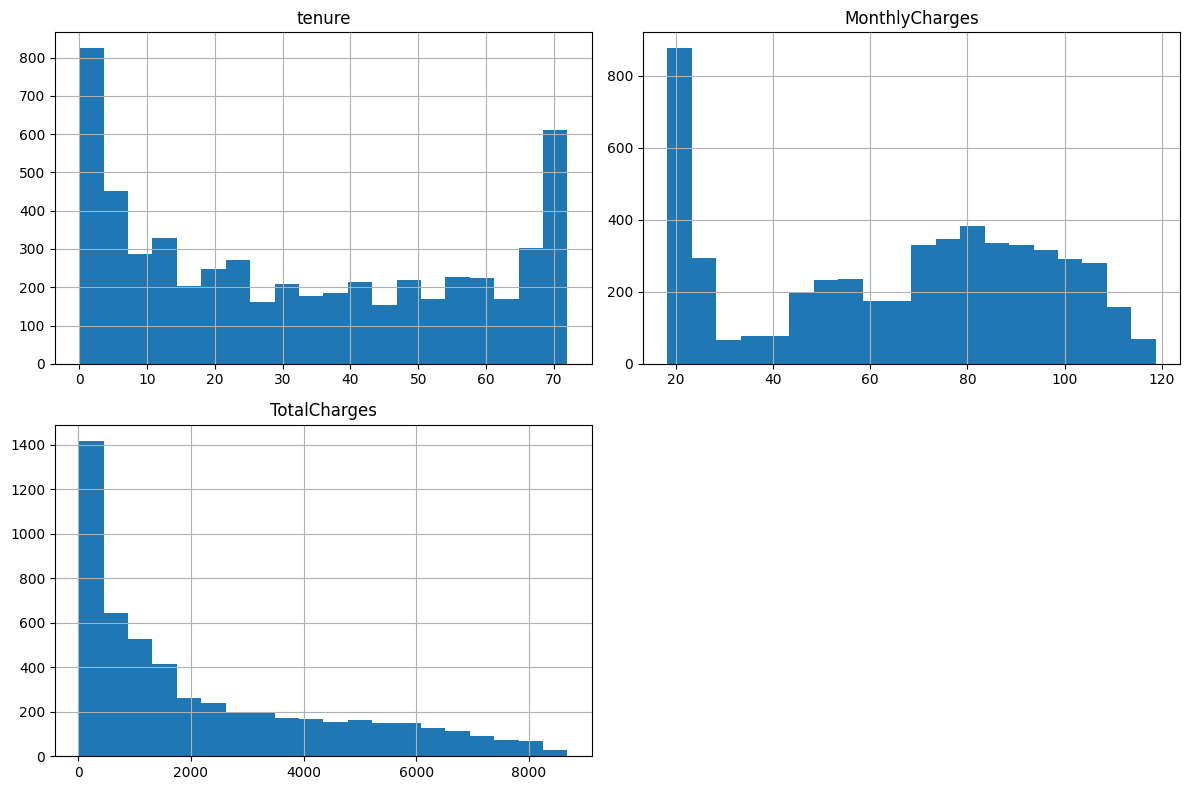

In [ ]:
# Distribution of numerical features
eda_df[numerical_features].hist(figsize=(12, 8), bins=20)
plt.tight_layout()
plt.show()

**Numerical features:** `tenure` ranges from 0 to 72 months and `MonthlyCharges` from about 18 to 119. `TotalCharges` is skewed towards lower values because many customers are fairly new.

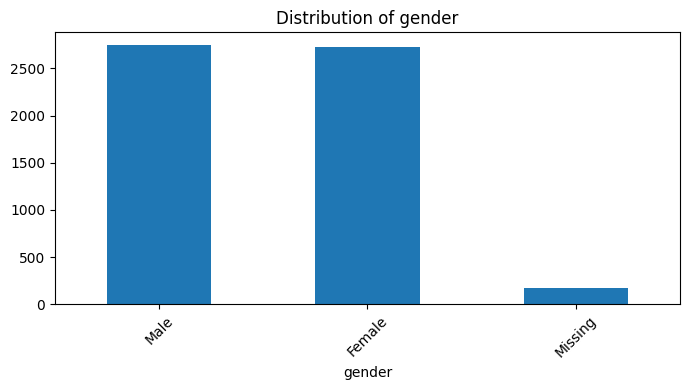

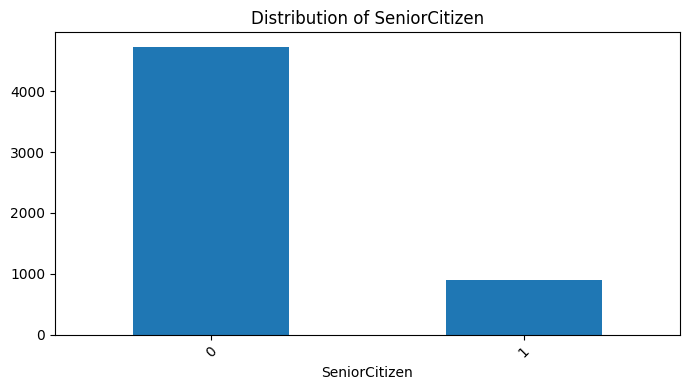

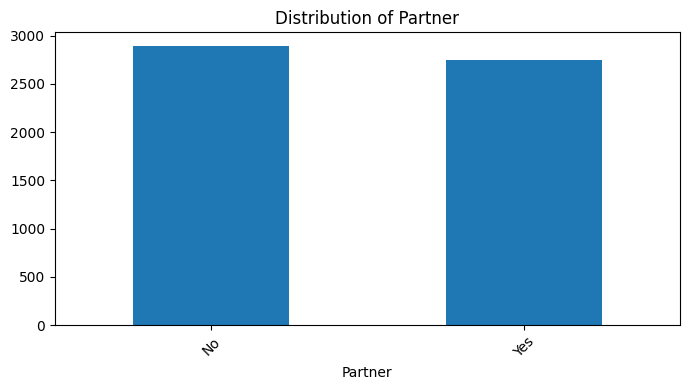

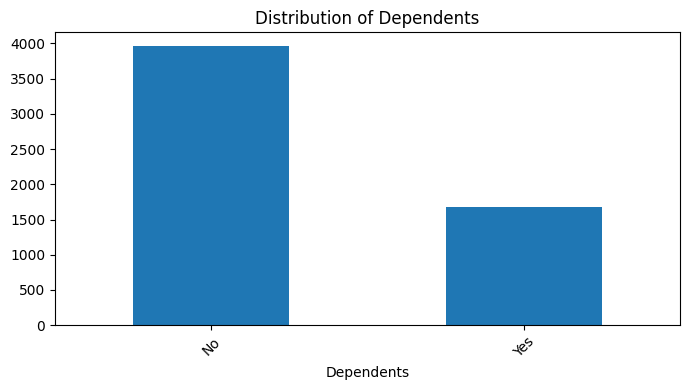

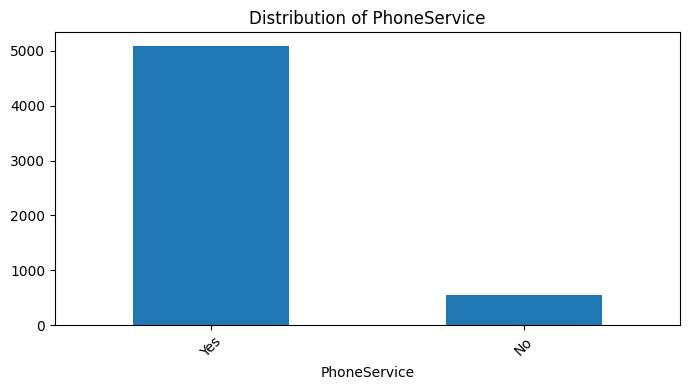

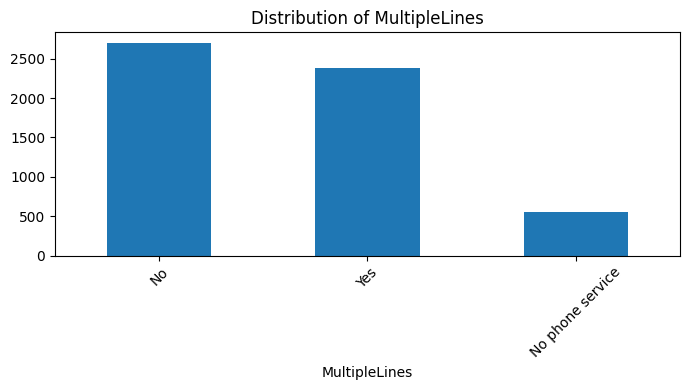

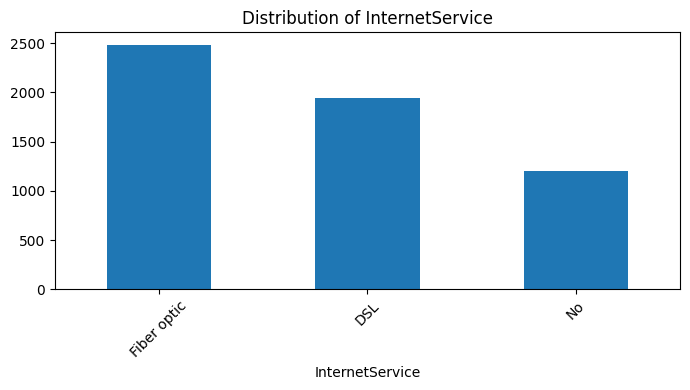

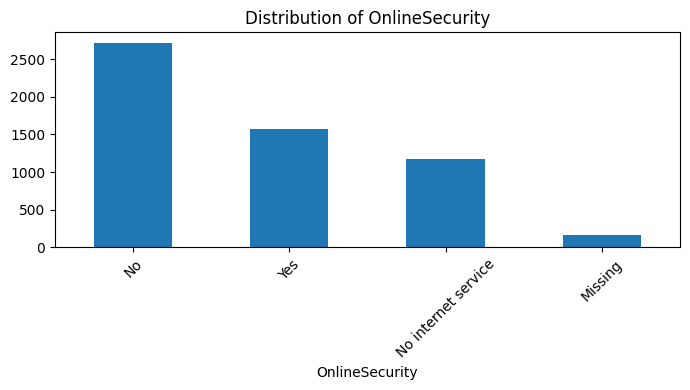

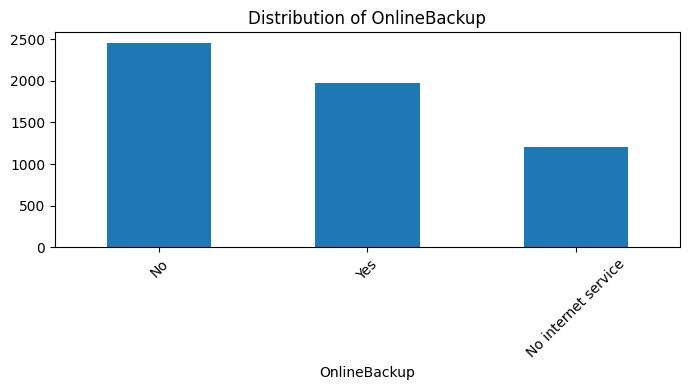

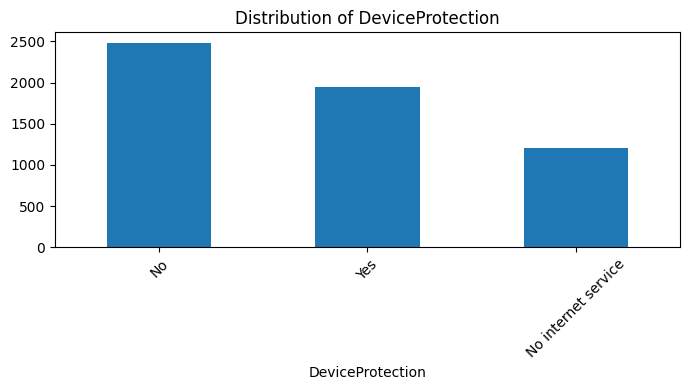

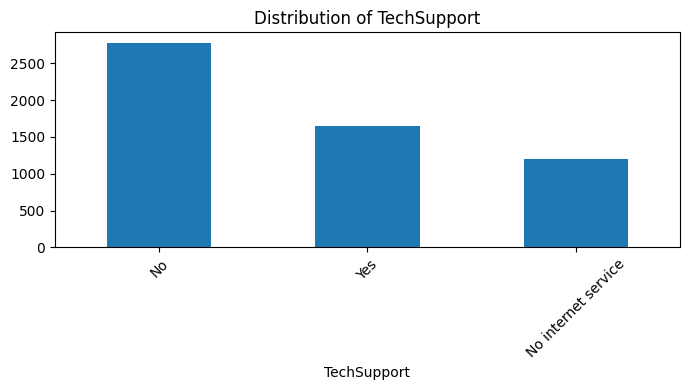

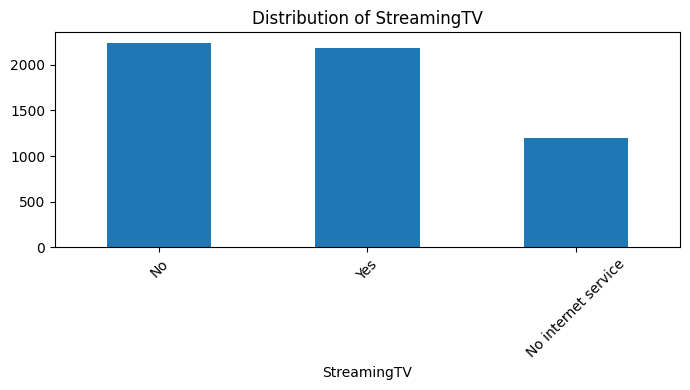

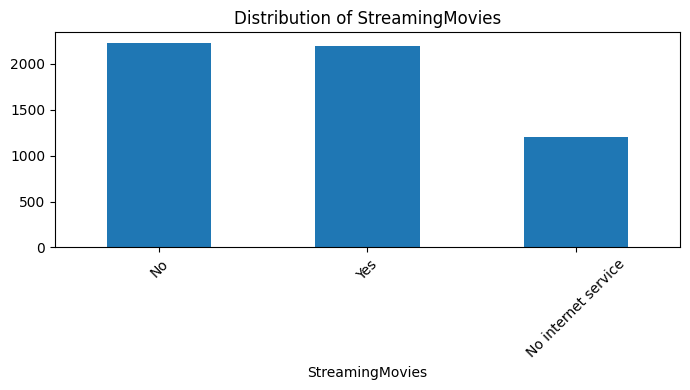

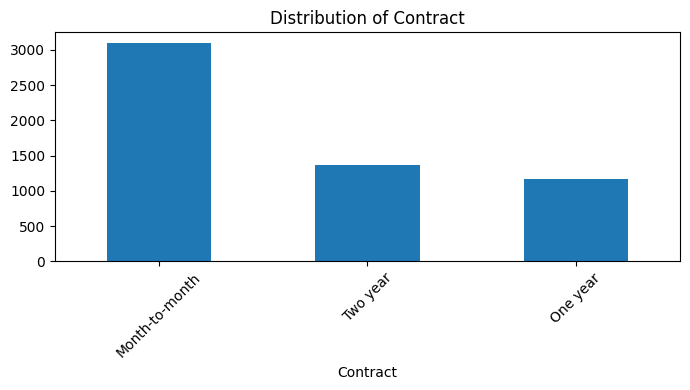

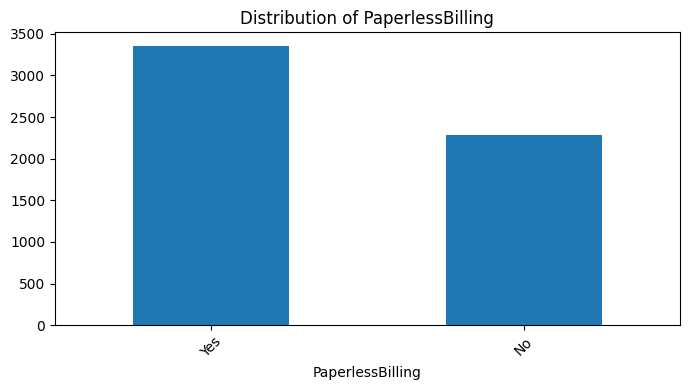

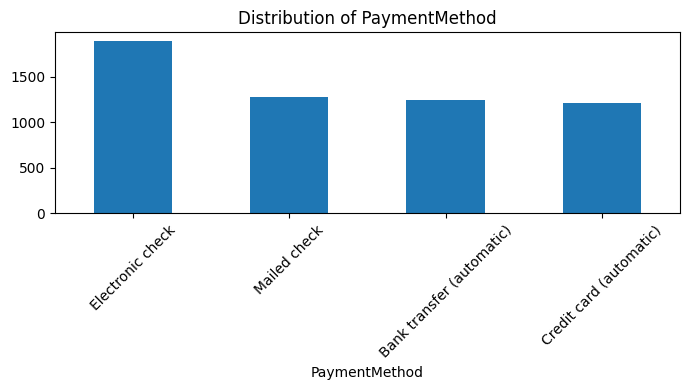

In [ ]:
# Distribution of categorical features
for col in categorical_features:
    plt.figure(figsize=(7, 4))
    eda_df[col].fillna('Missing').value_counts().plot(kind='bar')
    plt.title('Distribution of ' + col)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

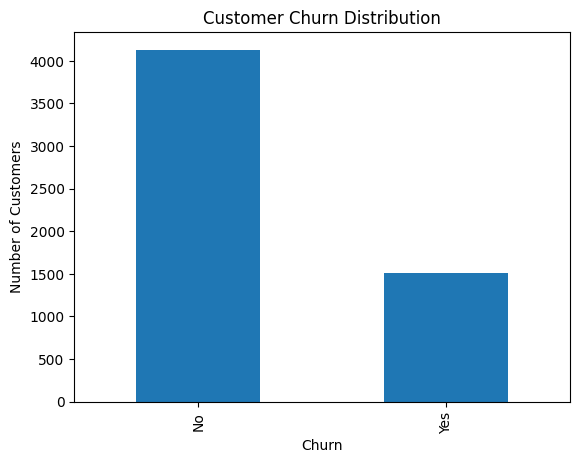

In [ ]:
# Churn distribution
eda_df['Churn'].value_counts().plot(kind='bar')
plt.title('Customer Churn Distribution')
plt.xlabel('Churn')
plt.ylabel('Number of Customers')
plt.show()

<Figure size 600x400 with 0 Axes>

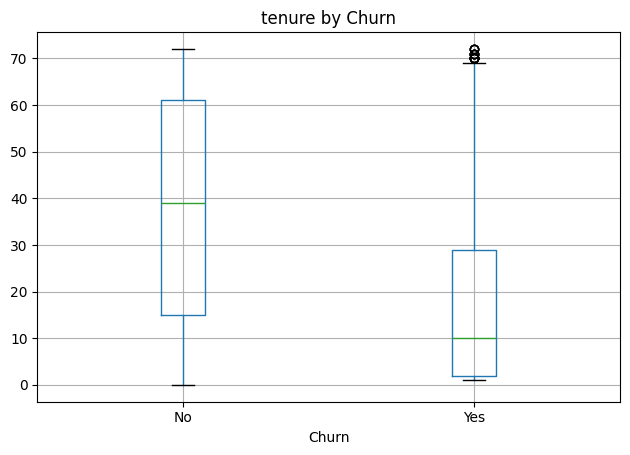

<Figure size 600x400 with 0 Axes>

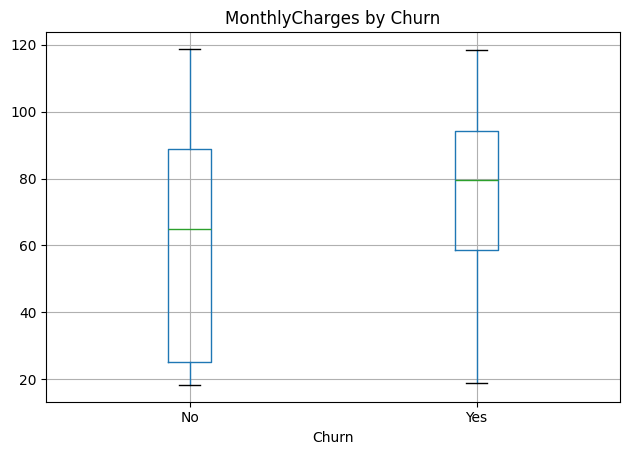

<Figure size 600x400 with 0 Axes>

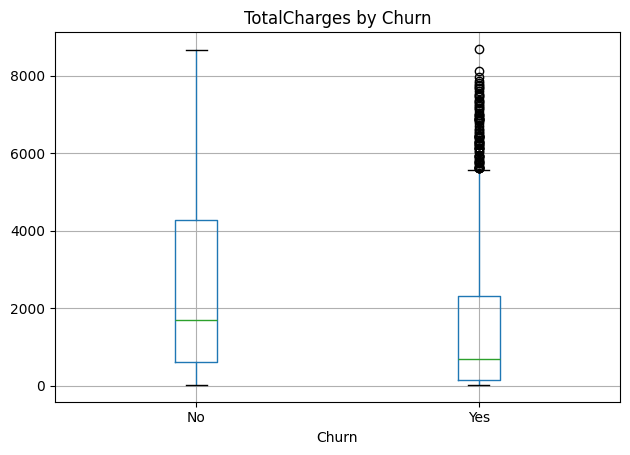

In [ ]:
# Relationship between numerical features and churn
for col in numerical_features:
    plt.figure(figsize=(6, 4))
    eda_df.boxplot(column=col, by='Churn')
    plt.title(col + ' by Churn')
    plt.suptitle('')
    plt.xlabel('Churn')
    plt.tight_layout()
    plt.show()

**Numerical features and churn:** Customers who churned have a much shorter median tenure (10 months vs 39 months) and higher median monthly charges (79.6 vs 64.9). Their median total charges are lower (680 vs 1,686) because they stay for less time.

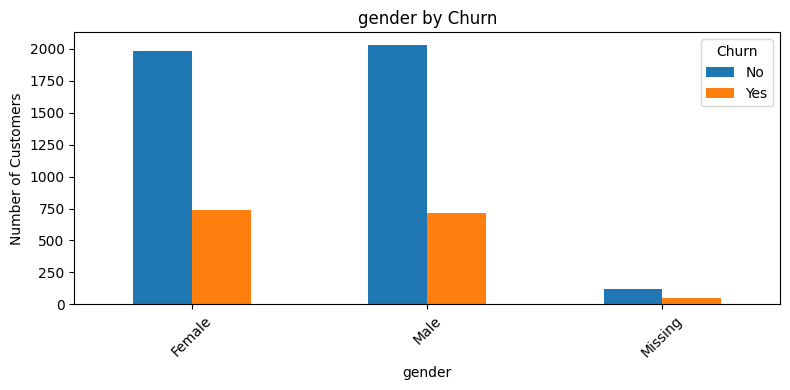

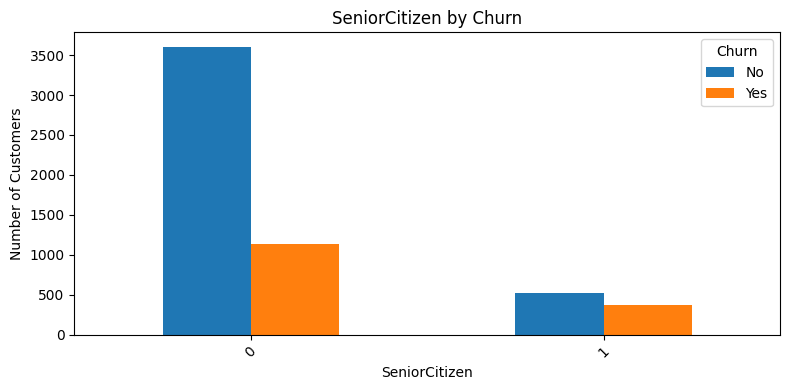

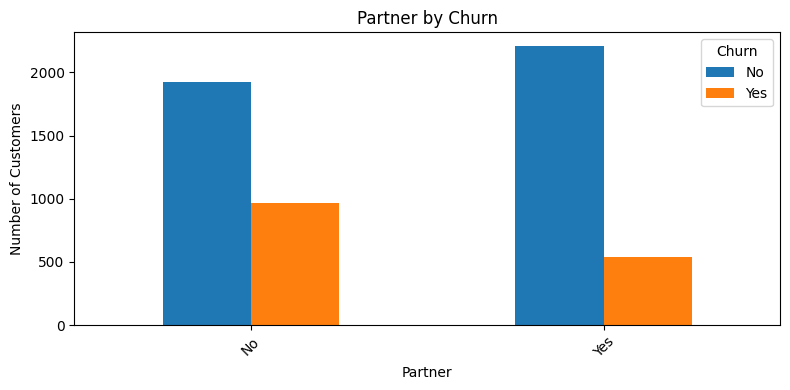

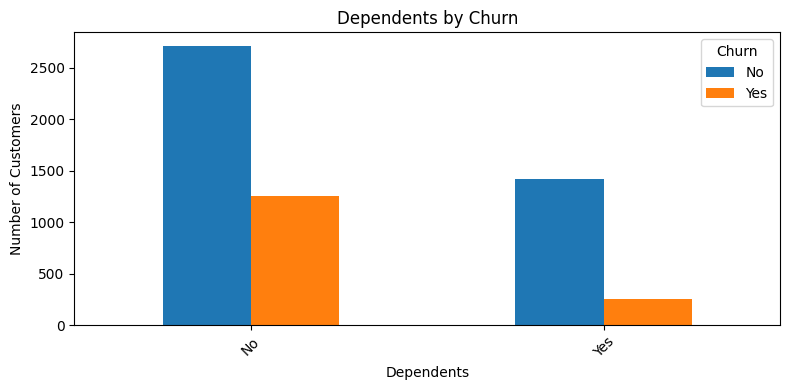

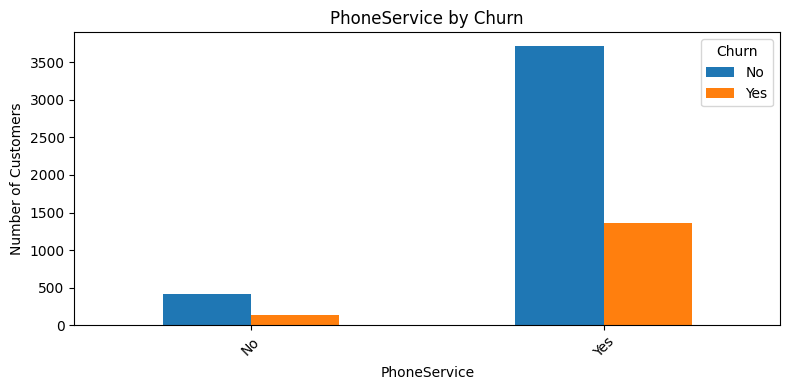

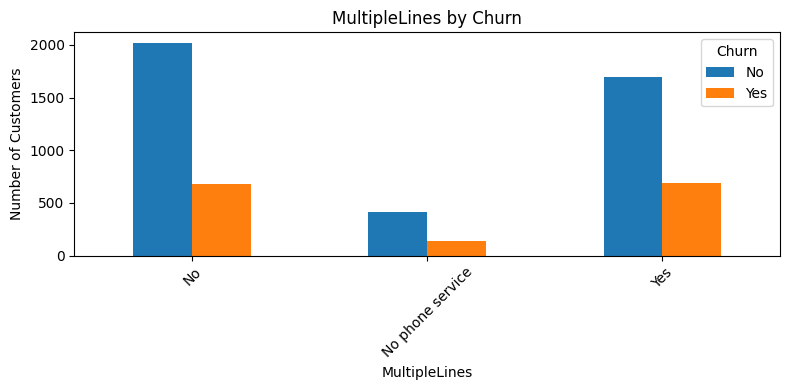

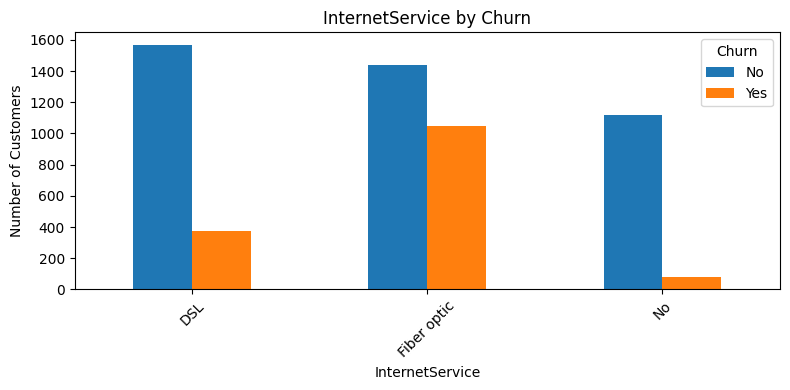

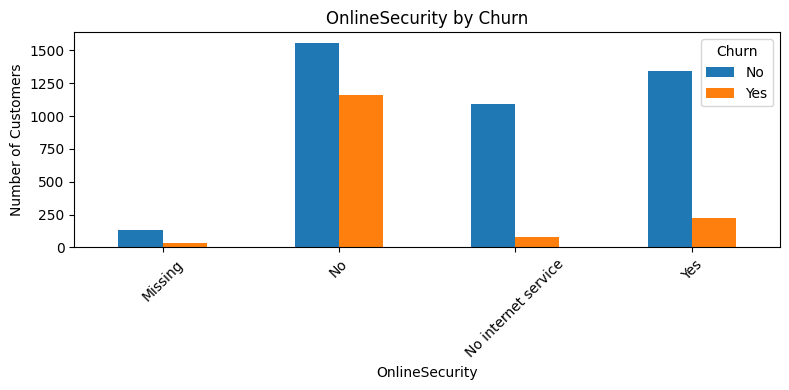

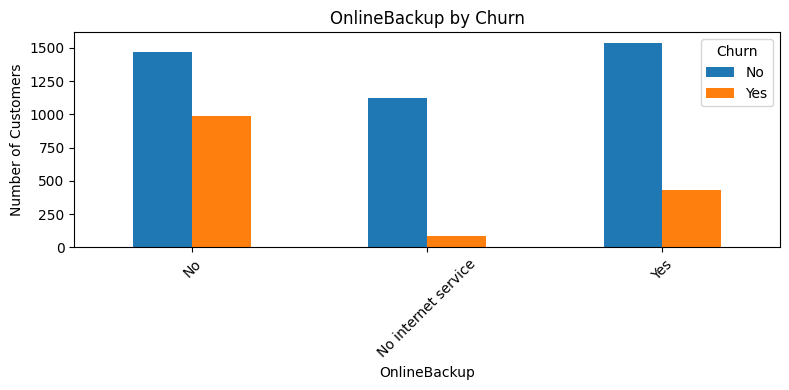

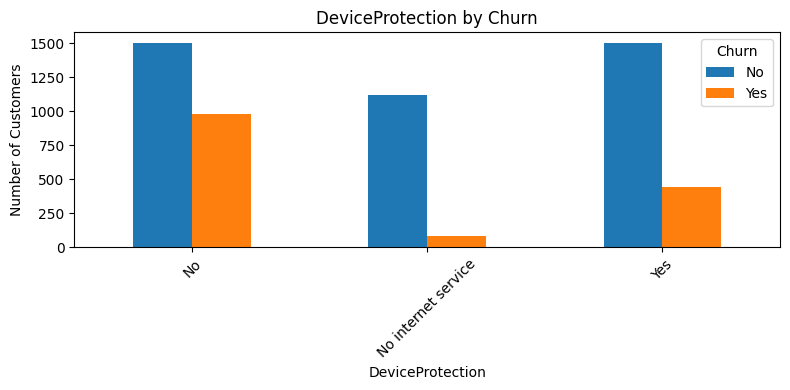

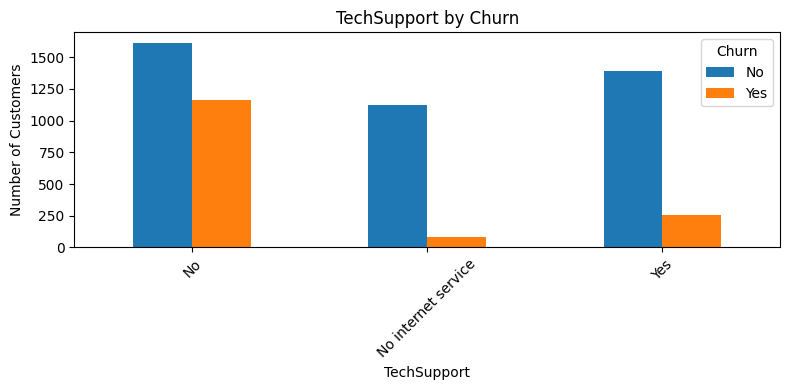

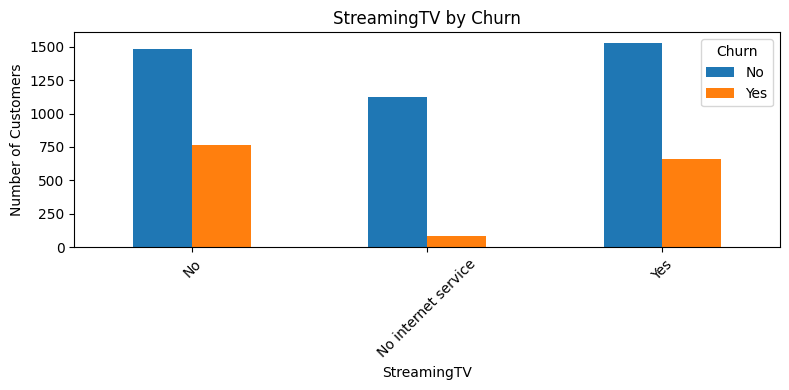

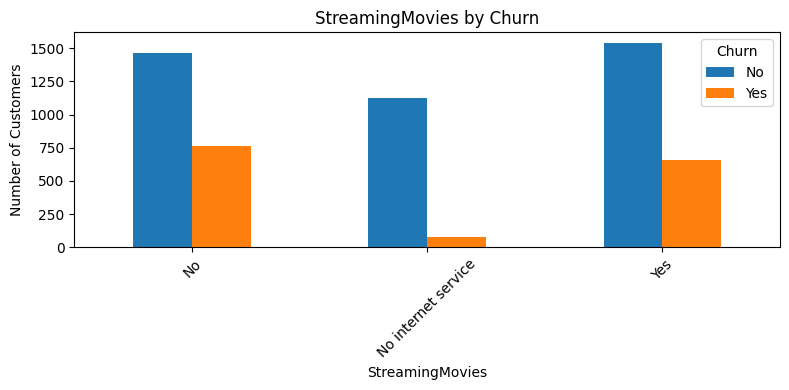

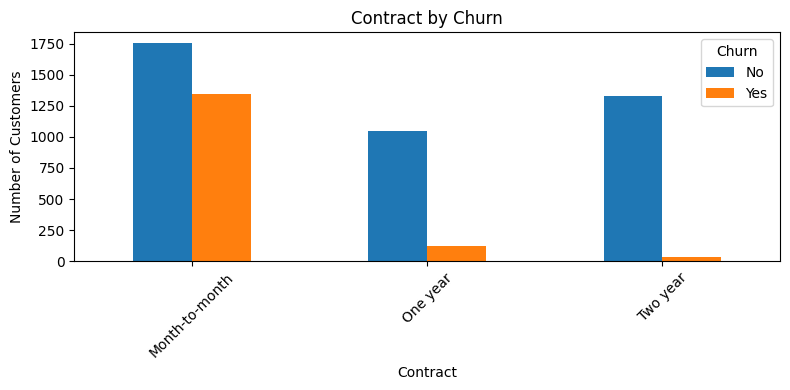

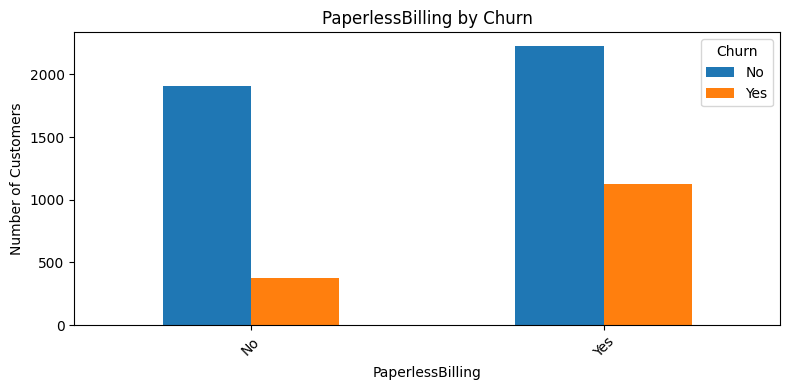

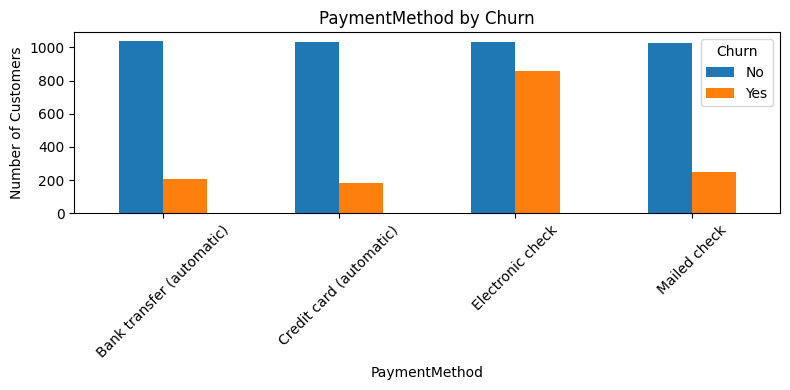

In [ ]:
# Relationship between categorical features and churn
for col in categorical_features:
    plt.figure(figsize=(8, 4))
    pd.crosstab(eda_df[col].fillna('Missing'), eda_df['Churn']).plot(kind='bar', ax=plt.gca())
    plt.title(col + ' by Churn')
    plt.xlabel(col)
    plt.ylabel('Number of Customers')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

**Categorical features and churn:**
- Month-to-month contracts churn the most (43.3%), compared with one-year (10.7%) and two-year (2.8%) contracts.
- Fiber optic customers churn at 42.1%, compared with 19.3% for DSL and 6.8% for customers without internet.
- Electronic check users churn at 45.3%; customers on automatic payments churn at about 15-17%.
- Customers without online security or tech support churn at about 42%, compared with about 14-16% for customers who have them.
- Senior citizens (41.7%), customers without a partner (33.5%) and customers without dependents (31.6%) churn more.
- Gender has almost no effect (27.2% for females, 26.1% for males).

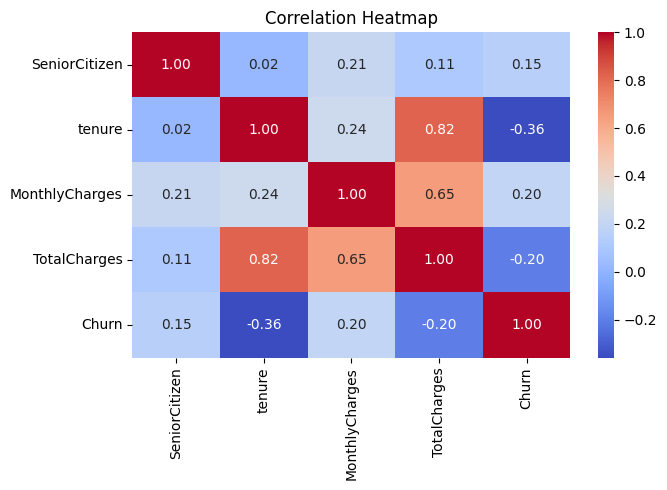

In [ ]:
# Correlation between numerical features and churn
correlation_df = eda_df[['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']].copy()
correlation_df['Churn'] = eda_df['Churn'].map({'No': 0, 'Yes': 1})

plt.figure(figsize=(7, 5))
sns.heatmap(correlation_df.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()

**Correlation:** `tenure` has the strongest relationship with churn (-0.36): longer tenure means less churn. `MonthlyCharges` has a weaker positive relationship (0.20). `tenure` and `TotalCharges` are strongly correlated (0.82), as expected, because total charges grow with time.

In [ ]:
# Check continuous numerical features for outliers using the IQR method
outlier_summary = []

for col in numerical_features:
    q1 = eda_df[col].quantile(0.25)
    q3 = eda_df[col].quantile(0.75)
    iqr = q3 - q1
    lower_limit = q1 - 1.5 * iqr
    upper_limit = q3 + 1.5 * iqr
    outliers = ((eda_df[col] < lower_limit) | (eda_df[col] > upper_limit)).sum()
    outlier_summary.append([col, outliers, lower_limit, upper_limit])

outlier_df = pd.DataFrame(outlier_summary, columns=['Feature', 'Outlier Count', 'Lower Limit', 'Upper Limit'])
display(outlier_df)

,Feature,Outlier Count,Lower Limit,Upper Limit
0,tenure,0,-61.5000,126.5000
1,MonthlyCharges,0,-43.0750,169.9250
2,TotalCharges,0,-4651.0125,8835.9875


**EDA note:** `customerID` is an identifier, so it is not plotted or used as a predictor. `TotalCharges` is converted to numeric for analysis; blank or invalid entries become missing values.

The IQR check found no outliers in `tenure`, `MonthlyCharges` or `TotalCharges`, so no rows are removed or capped. The binary `SeniorCitizen` flag is not checked for outliers.

## 4. Data Cleaning

Remove duplicate rows if present and convert `TotalCharges` to numeric. The 9 customers with `tenure` equal to 0 have a blank `TotalCharges` because they have not been billed yet, so it is set to 0. All other missing values are handled in the preprocessing step: median for numerical columns and most frequent value for categorical columns.

In [ ]:
# Remove duplicate rows if any are present
train_df = train_df.drop_duplicates().copy()
test_df = test_df.drop_duplicates().copy()

# Convert TotalCharges to numeric
train_df['TotalCharges'] = pd.to_numeric(train_df['TotalCharges'], errors='coerce')
test_df['TotalCharges'] = pd.to_numeric(test_df['TotalCharges'], errors='coerce')

train_df.loc[train_df['tenure'] == 0, 'TotalCharges'] = 0
test_df.loc[test_df['tenure'] == 0, 'TotalCharges'] = 0

print('Training duplicates after cleaning:', train_df.duplicated().sum())
print('Testing duplicates after cleaning:', test_df.duplicated().sum())

Training duplicates after cleaning: 0
Testing duplicates after cleaning: 0


## 5. Feature Engineering

Two new features are created as suggested in the case study. `Tenure_Contract` combines tenure with contract type. `CustomerLifetimeValue` is a simple proxy calculated as tenure multiplied by monthly charges; it is not an accounting measure of actual lifetime value.

In [ ]:
# Create a contract level for the interaction feature
contract_level = {'Month-to-month': 1, 'One year': 2, 'Two year': 3}

# Combine tenure and contract type
train_df['Tenure_Contract'] = train_df['tenure'] * train_df['Contract'].map(contract_level)
test_df['Tenure_Contract'] = test_df['tenure'] * test_df['Contract'].map(contract_level)

# Create a customer lifetime value proxy
train_df['CustomerLifetimeValue'] = train_df['tenure'] * train_df['MonthlyCharges']
test_df['CustomerLifetimeValue'] = test_df['tenure'] * test_df['MonthlyCharges']

In [ ]:
# Check the created features
train_df[['tenure', 'Contract', 'Tenure_Contract', 'MonthlyCharges', 'CustomerLifetimeValue']].head()

,tenure,Contract,Tenure_Contract,MonthlyCharges,CustomerLifetimeValue
0,35,One year,70,20.75,726.25
1,28,Month-to-month,28,35.75,1001.00
2,56,Month-to-month,56,98.60,5521.60
3,39,Two year,117,20.45,797.55
4,43,One year,86,51.25,2203.75


## 6. Data Preprocessing: Encoding and Scaling

Split the training dataset into training and validation sets. Fit missing-value imputation, one-hot encoding, and scaling on the training split only, then apply the same fitted transformations to the validation and testing data.

In [ ]:
# Separate features and target
X = train_df.drop(columns=['customerID', 'Churn'])
y = train_df['Churn'].map({'No': 0, 'Yes': 1})

X_test = test_df.drop(columns=['customerID', 'Churn'])
y_test = test_df['Churn'].map({'No': 0, 'Yes': 1})

# Split training data into training and validation sets
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print('Training rows:', X_train.shape[0])
print('Validation rows:', X_val.shape[0])
print('Testing rows:', X_test.shape[0])

Training rows: 4507
Validation rows: 1127
Testing rows: 1409


In [ ]:
# Identify numerical and categorical columns
numeric_features = [
    'SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges',
    'Tenure_Contract', 'CustomerLifetimeValue'
]
categorical_features = [col for col in X_train.columns if col not in numeric_features]

# Preprocess numerical and categorical features
numeric_preprocessor = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_preprocessor = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('numeric', numeric_preprocessor, numeric_features),
    ('categorical', categorical_preprocessor, categorical_features)
])

# Fit preprocessing only on the training data
X_train_processed = preprocessor.fit_transform(X_train)
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

print('Preprocessing completed.')

Preprocessing completed.


## 7. Feature Selection

A Random Forest model is used to rank the preprocessed features by importance. The 15 highest-ranked features are selected for model development. Feature importance shows predictive usefulness in this model; it does not prove that a feature causes churn.

In [ ]:
# Fit a Random Forest to rank features
feature_selector = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
feature_selector.fit(X_train_processed, y_train)

feature_names = preprocessor.get_feature_names_out()
feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': feature_selector.feature_importances_
}).sort_values(by='Importance', ascending=False)

display(feature_importance.head(15))

,Feature,Importance
3,numeric__TotalCharges,0.109628
4,numeric__Tenure_Contract,0.104322
2,numeric__MonthlyCharges,0.100119
5,numeric__CustomerLifetimeValue,0.098684
1,numeric__tenure,0.087422
38,categorical__Contract_Month-to-month,0.054834
18,categorical__InternetService_Fiber optic,0.027965
29,categorical__TechSupport_No,0.026885
20,categorical__OnlineSecurity_No,0.025803
45,categorical__PaymentMethod_Electronic check,0.022854


In [ ]:
# Select the 15 most important features
selected_indices = feature_importance.head(15).index.to_numpy()
selected_features = feature_names[selected_indices]

X_train_selected = X_train_processed[:, selected_indices]
X_val_selected = X_val_processed[:, selected_indices]
X_test_selected = X_test_processed[:, selected_indices]

print('Selected features:')
print(selected_features)

Selected features:
['numeric__TotalCharges' 'numeric__Tenure_Contract'
 'numeric__MonthlyCharges' 'numeric__CustomerLifetimeValue'
 'numeric__tenure' 'categorical__Contract_Month-to-month'
 'categorical__InternetService_Fiber optic' 'categorical__TechSupport_No'
 'categorical__OnlineSecurity_No'
 'categorical__PaymentMethod_Electronic check'
 'categorical__OnlineBackup_No' 'numeric__SeniorCitizen'
 'categorical__gender_Female' 'categorical__gender_Male'
 'categorical__DeviceProtection_No']


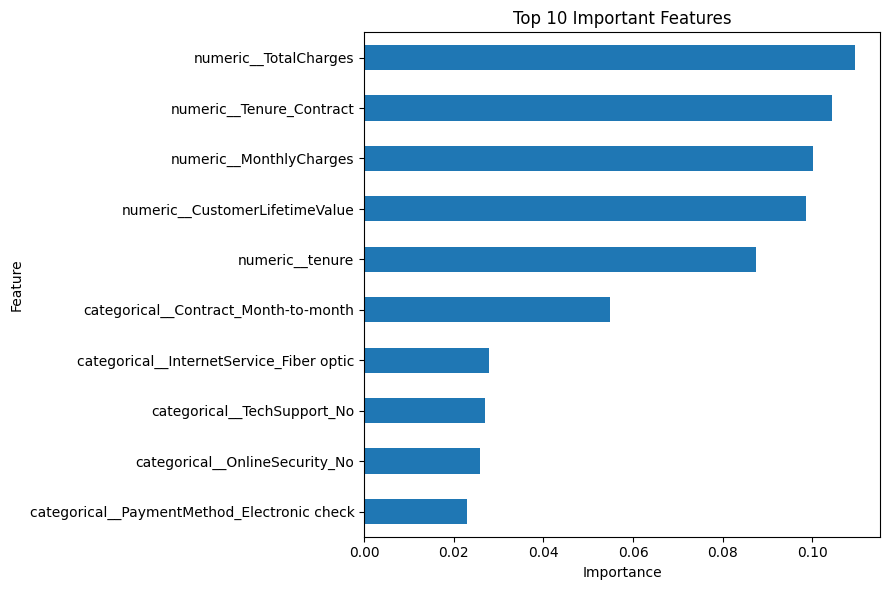

In [ ]:
# Visualize the selected features
feature_importance.head(10).sort_values(by='Importance').plot(
    kind='barh', x='Feature', y='Importance', legend=False, figsize=(9, 6)
)
plt.title('Top 10 Important Features')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()

## 8. Model Development

Three classification models are trained: Logistic Regression, Decision Tree, and Random Forest. The same training and validation data, preprocessing, and selected features are used for a fair comparison.

In [ ]:
# Create the classification models
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
}

trained_models = {}
results = []

# Train and evaluate each model on the validation set
for name, model in models.items():
    model.fit(X_train_selected, y_train)
    predictions = model.predict(X_val_selected)
    trained_models[name] = model

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_val, predictions),
        'Precision': precision_score(y_val, predictions, zero_division=0),
        'Recall': recall_score(y_val, predictions, zero_division=0),
        'F1 Score': f1_score(y_val, predictions, zero_division=0)
    })

results_df = pd.DataFrame(results).sort_values(by='F1 Score', ascending=False)
display(results_df)

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.802130,0.646617,0.571429,0.606702
2,Random Forest,0.787933,0.620155,0.531561,0.572451
1,Decision Tree,0.741792,0.516340,0.524917,0.520593


## 9. Model Evaluation and Comparison

Accuracy, precision, recall, F1-score, and the confusion matrix are used to evaluate the models. F1-score is used to select the model for tuning because it balances precision and recall. Recall is also important because it measures how many actual churn customers are identified.

In [ ]:
# Select the model with the highest validation F1-score
best_model_name = results_df.iloc[0]['Model']
best_model = trained_models[best_model_name]

print('Best model:', best_model_name)
print('Validation F1-score:', results_df.iloc[0]['F1 Score'])

best_predictions = best_model.predict(X_val_selected)
print(classification_report(y_val, best_predictions, target_names=['No Churn', 'Churn'], zero_division=0))

Best model: Logistic Regression
Validation F1-score: 0.6067019400352733
              precision    recall  f1-score   support

    No Churn       0.85      0.89      0.87       826
       Churn       0.65      0.57      0.61       301

    accuracy                           0.80      1127
   macro avg       0.75      0.73      0.74      1127
weighted avg       0.80      0.80      0.80      1127



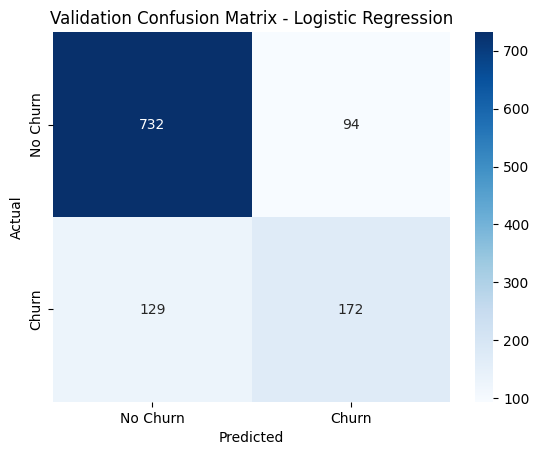

In [ ]:
# Confusion matrix for the best model
cm = confusion_matrix(y_val, best_predictions)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Churn', 'Churn'],
            yticklabels=['No Churn', 'Churn'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Validation Confusion Matrix - ' + best_model_name)
plt.show()

## 10. Hyperparameter Tuning

GridSearchCV tests a small set of parameter values using 3-fold cross-validation. The search is applied to the best model from the validation comparison. F1-score is the scoring metric because churn detection requires a balance between precision and recall.

The parameter grid depends on the selected model: Logistic Regression tests `C` (regularization strength); Decision Tree tests tree depth and minimum samples per split or leaf; Random Forest tests the number of trees, maximum depth, and minimum samples per split. Every grid also tests `class_weight`, because only about 27% of customers churn and `'balanced'` gives the churn class more importance.

In [ ]:
# Set the parameter grid for the selected model
if best_model_name == 'Logistic Regression':
    param_grid = {'C': [0.1, 1, 10], 'class_weight': [None, 'balanced']}
elif best_model_name == 'Decision Tree':
    param_grid = {
        'max_depth': [None, 5, 10],
        'min_samples_split': [2, 10],
        'min_samples_leaf': [1, 5],
        'class_weight': [None, 'balanced']
    }
else:
    param_grid = {
        'n_estimators': [100, 200],
        'max_depth': [None, 10],
        'min_samples_split': [2, 5],
        'class_weight': [None, 'balanced']
    }

# Run GridSearchCV
grid_search = GridSearchCV(
    estimator=best_model,
    param_grid=param_grid,
    cv=3,
    scoring='f1',
    n_jobs=-1
)
grid_search.fit(X_train_selected, y_train)

tuned_model = grid_search.best_estimator_
print('Best parameters:', grid_search.best_params_)
print('Best cross-validation F1-score:', grid_search.best_score_)

Best parameters: {'C': 1, 'class_weight': 'balanced'}
Best cross-validation F1-score: 0.631356171764291


In [ ]:
# Compare validation performance before and after tuning
before_tuning = f1_score(y_val, best_model.predict(X_val_selected))
after_tuning = f1_score(y_val, tuned_model.predict(X_val_selected))

print('F1-score before tuning:', before_tuning)
print('F1-score after tuning:', after_tuning)

if after_tuning > before_tuning:
    print('Hyperparameter tuning improved the validation F1-score.')
elif after_tuning < before_tuning:
    print('Hyperparameter tuning did not improve the validation F1-score.')
else:
    print('Hyperparameter tuning made no change to the validation F1-score.')

F1-score before tuning: 0.6067019400352733
F1-score after tuning: 0.6304635761589404
Hyperparameter tuning improved the validation F1-score.


**Choice of hyperparameters:** `C` controls regularization strength, so values from 0.1 to 10 cover strong, default and weak regularization. `class_weight='balanced'` is tested because the churn class is much smaller than the no-churn class. A small grid with 3-fold cross-validation keeps the search fast and easy to follow.

The search selected `C=1` with `class_weight='balanced'`. The validation F1-score improved from 0.607 to 0.630, mainly because the balanced setting helps the model find more of the customers who churn.

In [ ]:
# Use the tuned model only if it improved the validation F1-score
if after_tuning > before_tuning:
    final_model = tuned_model
    print('Final model: tuned', best_model_name)
else:
    final_model = best_model
    print('Final model: original', best_model_name)

Final model: tuned Logistic Regression


## 11. Final Evaluation on the Testing Dataset

The testing dataset was not used to fit the preprocessing steps, select features, compare models, or tune hyperparameters. It is used here only for the final evaluation. The supplied testing dataset contains the actual `Churn` column, so the predictions can be compared with the known outcomes.

In [ ]:
# Predict churn for the testing dataset
test_predictions = final_model.predict(X_test_selected)

print('Testing Accuracy:', accuracy_score(y_test, test_predictions))
print('Testing Precision:', precision_score(y_test, test_predictions, zero_division=0))
print('Testing Recall:', recall_score(y_test, test_predictions, zero_division=0))
print('Testing F1-score:', f1_score(y_test, test_predictions, zero_division=0))

Testing Accuracy: 0.723207948899929
Testing Precision: 0.4784110535405872
Testing Recall: 0.7589041095890411
Testing F1-score: 0.586864406779661


In [ ]:
# Classification report on the testing dataset
print(classification_report(y_test, test_predictions, target_names=['No Churn', 'Churn'], zero_division=0))

              precision    recall  f1-score   support

    No Churn       0.89      0.71      0.79      1044
       Churn       0.48      0.76      0.59       365

    accuracy                           0.72      1409
   macro avg       0.69      0.73      0.69      1409
weighted avg       0.79      0.72      0.74      1409



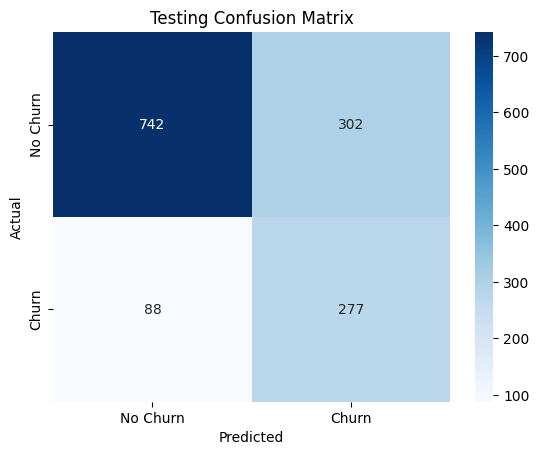

In [ ]:
# Confusion matrix on the testing dataset
test_cm = confusion_matrix(y_test, test_predictions)
sns.heatmap(test_cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Churn', 'Churn'],
            yticklabels=['No Churn', 'Churn'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Testing Confusion Matrix')
plt.show()

In [ ]:
# Summary of final results
print('Selected model:', best_model_name)
print('Top important features:', list(selected_features[:10]))
print('Final testing accuracy:', round(accuracy_score(y_test, test_predictions), 4))
print('Final testing precision:', round(precision_score(y_test, test_predictions, zero_division=0), 4))
print('Final testing recall:', round(recall_score(y_test, test_predictions, zero_division=0), 4))
print('Final testing F1-score:', round(f1_score(y_test, test_predictions, zero_division=0), 4))

Selected model: Logistic Regression
Top important features: ['numeric__TotalCharges', 'numeric__Tenure_Contract', 'numeric__MonthlyCharges', 'numeric__CustomerLifetimeValue', 'numeric__tenure', 'categorical__Contract_Month-to-month', 'categorical__InternetService_Fiber optic', 'categorical__TechSupport_No', 'categorical__OnlineSecurity_No', 'categorical__PaymentMethod_Electronic check']
Final testing accuracy: 0.7232
Final testing precision: 0.4784
Final testing recall: 0.7589
Final testing F1-score: 0.5869


## 12. Conclusion and Business Recommendations

### Conclusion

- The training data has 5,634 customers (26.7% churned) and the testing data has 1,409 customers. Missing values were found in `gender`, `OnlineSecurity`, `MonthlyCharges` and `TotalCharges`, and no outliers or duplicates were found.
- Three models were compared on the validation set: Logistic Regression (F1 0.607), Random Forest (F1 0.572) and Decision Tree (F1 0.521). Logistic Regression performed best.
- GridSearchCV selected `C=1` and `class_weight='balanced'`, which improved the validation F1-score from 0.607 to 0.630.
- On the separate testing data, the tuned model reached accuracy 0.723, precision 0.478, recall 0.759 and F1-score 0.587.
- Tuning with balanced class weights increased recall (more churners are found) but lowered precision and accuracy (more non-churners are flagged). This trade-off suits a retention campaign where missing a churner is costly.
- The most important features were `TotalCharges`, `Tenure_Contract`, `MonthlyCharges`, `CustomerLifetimeValue`, `tenure` and month-to-month contracts. Both engineered features ranked in the top five.

### Business Recommendations

1. Focus retention offers on month-to-month customers, who churn at 43.3%, and encourage them to move to one-year or two-year contracts.
2. Target new customers with short tenure, since churn is highest early in the customer relationship.
3. Review the fiber optic service and electronic check payments, which have the highest churn rates (42.1% and 45.3%). Offer incentives to move to automatic payments.
4. Promote online security and tech support, because customers with these services churn much less.
5. Use the model's churn predictions to build the retention list, and test each offer to confirm that it reduces churn.
6. Monitor precision and recall over time and retrain the model as customer behaviour changes.

Feature importance and the patterns above show association with churn, not proof of cause.